In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
url = 'https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-stewardship-ibtracs/v04r01/access/csv/ibtracs.ALL.list.v04r01.csv'
df = pd.read_csv(url, parse_dates=['ISO_TIME'], usecols=range(12),
                 skiprows=[1], na_values=[' ', 'NOT_NAMED'],
                 keep_default_na=False, dtype={'NAME': str})

In [9]:
dfnamed = df.groupby("NAME").agg(MAX_WIND=('WMO_WIND','max'),
                               MIN_PRES=('WMO_PRES','min'),
                               MEAN_LAT=('LAT','mean'),
                               MEAN_LON=('LON','mean'),
                               BASIN=('BASIN','first'),
                               SUBBASIN=('SUBBASIN','first'),
                               NATURE=('NATURE','first'),
                               SEASON=('SEASON','first')).reset_index()
dfnamed.head()

,NAME,MAX_WIND,MIN_PRES,MEAN_LAT,MEAN_LON,BASIN,SUBBASIN,NATURE,SEASON
0,ABAIMBA,43.0,995.0,-4.637234,63.031915,SI,MM,TS,2003
1,ABBY,120.0,895.0,20.905938,74.640937,NA,NA,TS,1960
2,ABE,85.0,945.0,22.272561,128.743293,WP,MM,NR,1990
3,ABEL:BETH,60.0,975.0,15.482927,131.466667,WP,MM,NR,1996
4,ABELA,50.0,987.0,-10.850769,65.370769,SI,MM,DS,2017


In [10]:
import gc
del df
gc.collect()

31

In [5]:
len(dfnamed)

1904

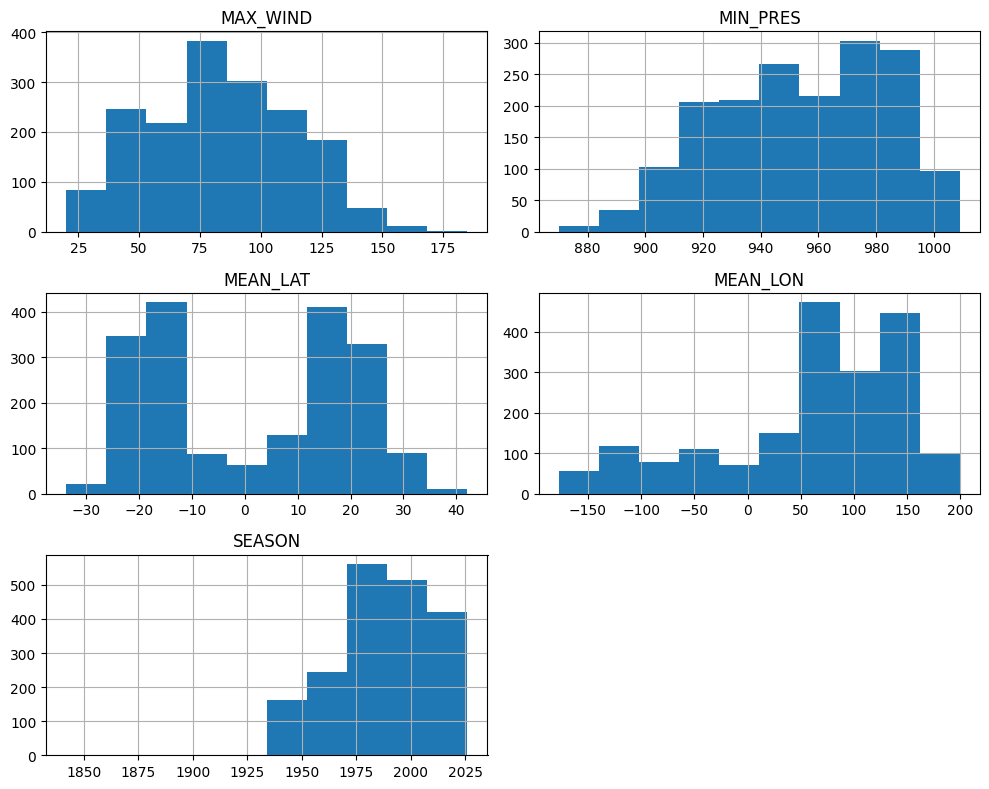

In [11]:
dfnamed.hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

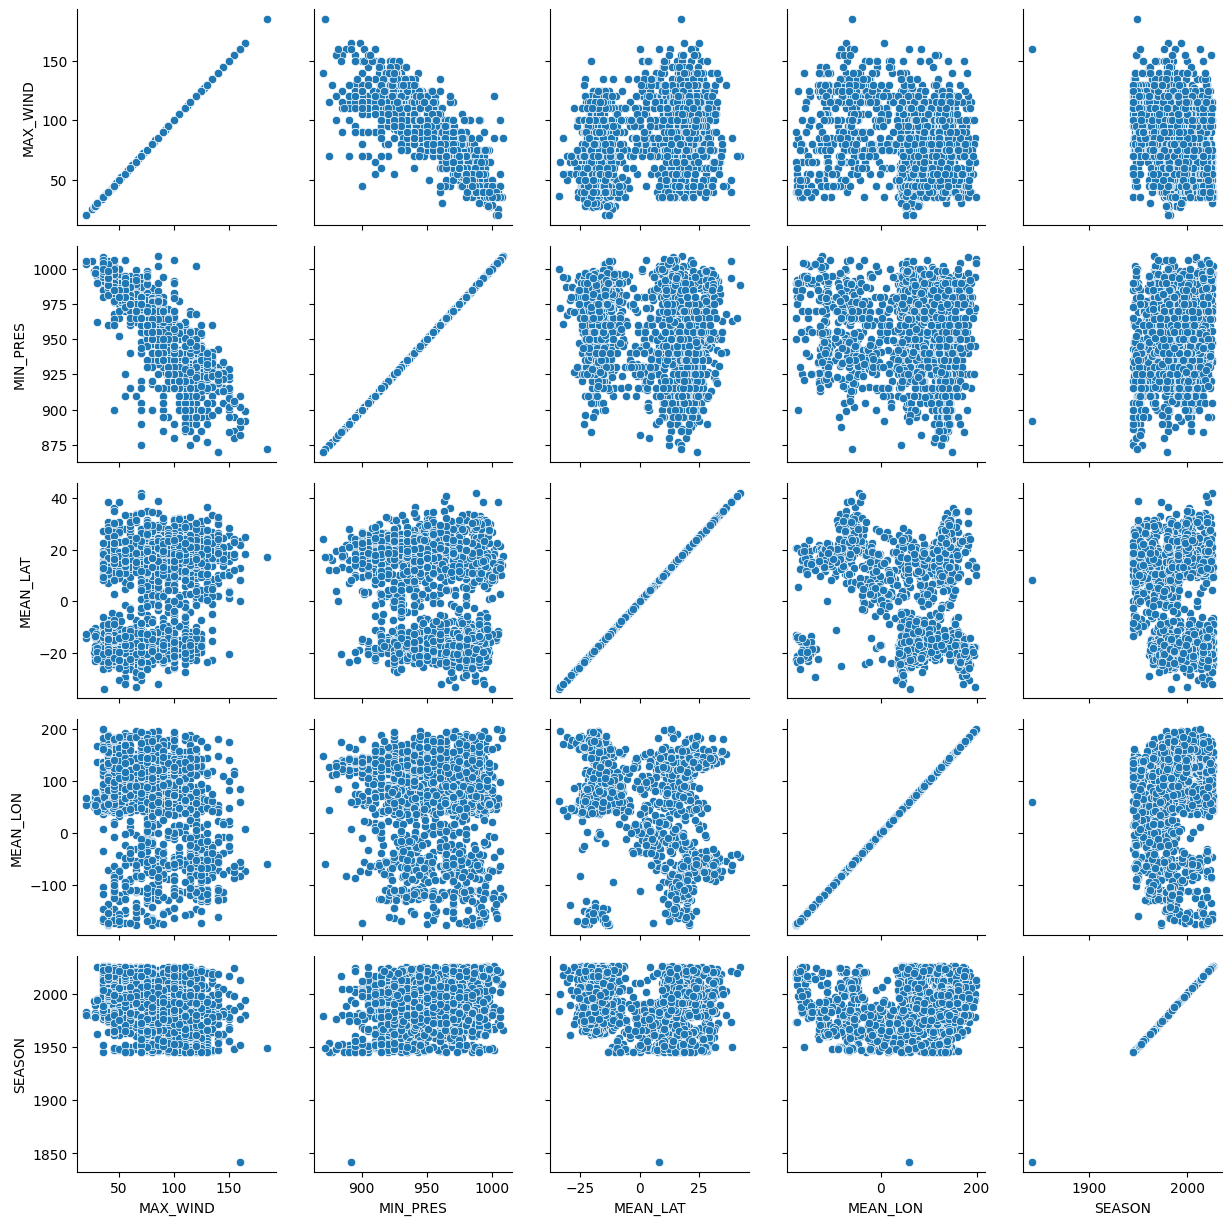

In [12]:
g = sns.PairGrid(dfnamed)
g.map(sns.scatterplot)
plt.show()

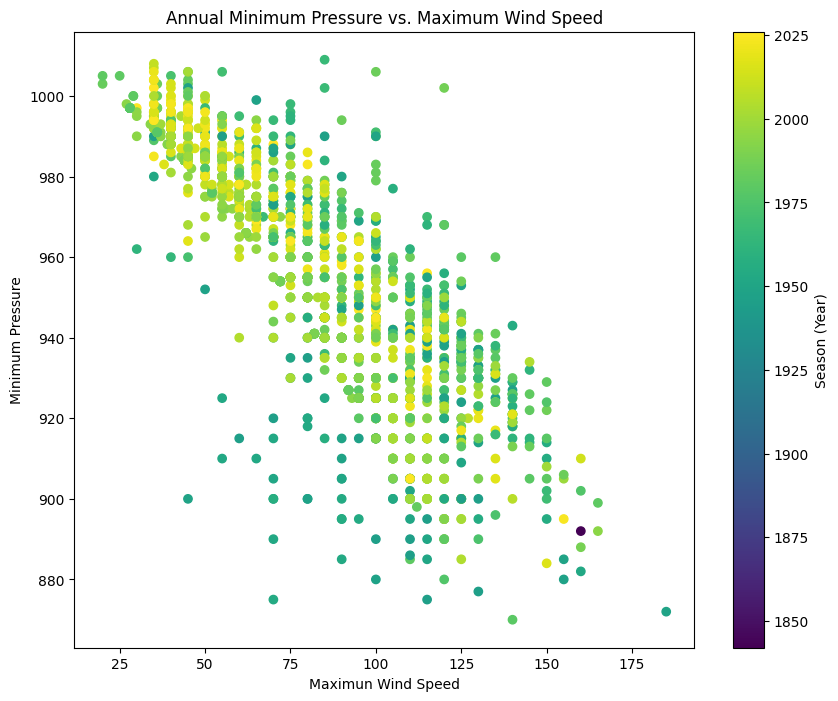

In [13]:
plt.figure(figsize=(10, 8))
sc = plt.scatter(dfnamed['MAX_WIND'], dfnamed['MIN_PRES'],
                  c=dfnamed['SEASON'], cmap='viridis')
plt.xlabel('Maximun Wind Speed')
plt.ylabel('Minimum Pressure')
plt.colorbar(sc, label='Season (Year)')
plt.title('Annual Minimum Pressure vs. Maximum Wind Speed')
plt.show()

In [14]:
dfnamed.count()

,0
NAME,1904
MAX_WIND,1719
MIN_PRES,1731
MEAN_LAT,1904
MEAN_LON,1904
BASIN,1904
SUBBASIN,1904
NATURE,1904
SEASON,1904


In [15]:
dfdrop = dfnamed.dropna()
dfdrop.shape

(1682, 9)

In [16]:
dfimputed = dfnamed.fillna(0.0)
dfimputed.shape

(1904, 9)

In [17]:
from sklearn.preprocessing import StandardScaler

wind_scaler = StandardScaler()
y = wind_scaler.fit_transform(dfdrop['MAX_WIND'].values.reshape(-1, 1))
y.shape

(1682, 1)

In [18]:
dffeatures = dfdrop.copy()
dffeatures = dffeatures.drop(columns=['NAME', 'MAX_WIND'])
dffeatures.head()

,MIN_PRES,MEAN_LAT,MEAN_LON,BASIN,SUBBASIN,NATURE,SEASON
0,995.0,-4.637234,63.031915,SI,MM,TS,2003
1,895.0,20.905938,74.640937,NA,NA,TS,1960
2,945.0,22.272561,128.743293,WP,MM,NR,1990
3,975.0,15.482927,131.466667,WP,MM,NR,1996
4,987.0,-10.850769,65.370769,SI,MM,DS,2017


In [19]:
print(dffeatures['BASIN'].unique())
print(dffeatures['SUBBASIN'].unique())
print(dffeatures['NATURE'].unique())

['SI' 'NA' 'WP' 'SP' 'EP' 'NI']
['MM' 'NA' 'EA' 'WA' 'BB' 'CP' 'GM' 'AS' 'CS']
['TS' 'NR' 'DS' 'MX' 'SS' 'ET']


In [20]:
print(dffeatures['BASIN'].value_counts())
print(dffeatures['SUBBASIN'].value_counts())
print(dffeatures['NATURE'].value_counts())

BASIN
SI    550
WP    464
SP    246
EP    175
NA    174
NI     73
Name: count, dtype: int64
SUBBASIN
MM    1115
WA     199
NA     113
EA      88
BB      49
CS      36
CP      33
GM      25
AS      24
Name: count, dtype: int64
NATURE
TS    1120
DS     305
NR     155
MX      79
SS      16
ET       7
Name: count, dtype: int64


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = ['BASIN', 'SUBBASIN', 'NATURE']
numeric_cols = ['MIN_PRES', 'MEAN_LAT', 'MEAN_LON', 'SEASON']

ct = ColumnTransformer([
    ('cat', OneHotEncoder(), categorical_cols),
    ('num', StandardScaler(), numeric_cols)
])

X = ct.fit_transform(dffeatures)
X.shape

(1682, 25)

In [22]:
ct.get_feature_names_out()

array(['cat__BASIN_EP', 'cat__BASIN_NA', 'cat__BASIN_NI', 'cat__BASIN_SI',
       'cat__BASIN_SP', 'cat__BASIN_WP', 'cat__SUBBASIN_AS',
       'cat__SUBBASIN_BB', 'cat__SUBBASIN_CP', 'cat__SUBBASIN_CS',
       'cat__SUBBASIN_EA', 'cat__SUBBASIN_GM', 'cat__SUBBASIN_MM',
       'cat__SUBBASIN_NA', 'cat__SUBBASIN_WA', 'cat__NATURE_DS',
       'cat__NATURE_ET', 'cat__NATURE_MX', 'cat__NATURE_NR',
       'cat__NATURE_SS', 'cat__NATURE_TS', 'num__MIN_PRES',
       'num__MEAN_LAT', 'num__MEAN_LON', 'num__SEASON'], dtype=object)

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [24]:
X_val, X_test, y_val, y_test = train_test_split(
    X_test_val, y_test_val, test_size=0.5, random_state=42)

print('X_train:', X_train.shape, 'y_train:', y_train.shape)
print('X_val:  ', X_val.shape, 'y_val:  ', y_val.shape)
print('X_test: ', X_test.shape, 'y_test: ', y_test.shape)

X_train: (1345, 25) y_train: (1345, 1)
X_val:   (168, 25) y_val:   (168, 1)
X_test:  (169, 25) y_test:  (169, 1)


In [25]:
np.save('X_train.npy', X_train)
np.save('X_val.npy', X_val)
np.save('X_test.npy', X_test)
np.save('y_train.npy', y_train)
np.save('y_val.npy', y_val)
np.save('y_test.npy', y_test)